In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = '1'
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [3]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from scipy.stats import ks_2samp
from ndtest.ksnd import ks2d2s

from nreg.x_xerr import gen_xobs_trans_neglogplus, nf_fit_trans_neglogplus

In [4]:
x = np.random.uniform(1, 3, size=10000)
x_err = np.random.uniform(0.1, 0.5, size=10000) + x * 0.6
x_obs = np.random.normal(x, x_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)

In [5]:
optimizer = optax.adam(3e-3)

In [6]:
flow, loss, params = nf_fit_trans_neglogplus(x_obs,
                                             x_err,
                                             optimizer=optimizer,
                                             n_pre=100,
                                             n_train=1000,
                                             n_node=21,
                                             verbose=True,
                                             flow=None,
                                             x_min=0,
                                             x_max=x_obs.max(),
                                             x_err_min=0,
                                             x_err_max=x_err.max() * 1.2,
                                             check_per_step=10,
                                             early_stop=True,
                                             max_stuck=5,
                                             stuck_frac=0.01)

100%|██████████| 100/100 [00:08<00:00, 12.50it/s]


step 0: loss 1.751608967781067
step 10: loss 1.6148333549499512
step 20: loss 1.5913642644882202
step 30: loss 1.5819005966186523
step 40: loss 1.578134536743164
step 50: loss 1.575246810913086
step 60: loss 1.5731679201126099
step 70: loss 1.5732033252716064
step 80: loss 1.5727204084396362


In [9]:
x_gen, x_err_gen, x_obs_gen = gen_xobs_trans_neglogplus(flow, 10000, 0, x_obs.max(), 0, x_err.max() * 1.2, params, return_numpy=True)

In [10]:
ks_2samp(x_obs, x_obs_gen)

KstestResult(statistic=0.0179, pvalue=0.08118453676750115, statistic_location=3.2731423, statistic_sign=1)

In [11]:
ks_2samp(x_err, x_err_gen)

KstestResult(statistic=0.0115, pvalue=0.5228883388356883, statistic_location=1.4913914, statistic_sign=-1)

In [12]:
ks_2samp(x_gen, x)

KstestResult(statistic=0.1101, pvalue=3.5610465160063985e-53, statistic_location=2.999248664099526, statistic_sign=-1)

In [13]:
ks2d2s(x_obs, x_err, x_obs_gen, x_err_gen)

(0.025550000369548798, 0.026145204467562373)

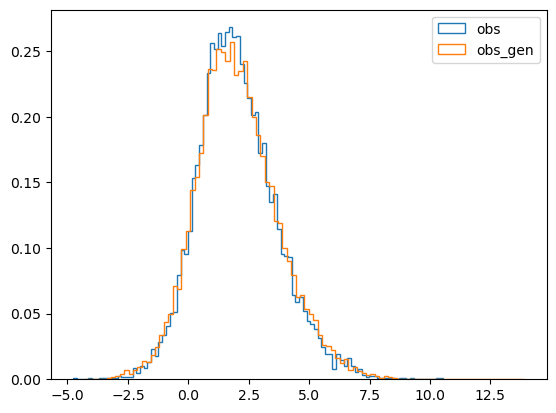

In [14]:
plt.hist(x_obs, bins=100, histtype='step', density=True, label='obs');
plt.hist(x_obs_gen, bins=100, histtype='step', density=True, label='obs_gen');
plt.legend()

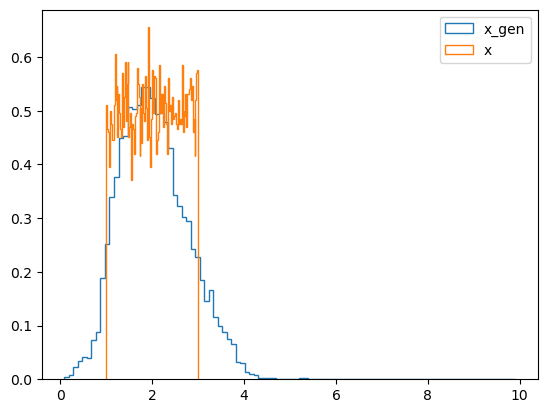

In [15]:
plt.hist(x_gen, bins=100, histtype='step', density=True, label='x_gen');
plt.hist(x, bins=100, histtype='step', density=True, label='x');
plt.legend()